In [1]:
from Influence_Modelling import Network, XsvNetwork, Sampling, Heuristics
from matplotlib import pyplot as plt
import scienceplots

plt.style.use(["science", "no-latex"])

en = XsvNetwork.XsvNetwork("", "", "enron")
net = Network.Network("Enron")
net.set_nx(Sampling.snowball_sample(en.get_nx(), 1024))

a, b, c = net.run_ICC(Heuristics.deg_h(net.get_nx(), 50))
d, e, f = net.run_ICC(Heuristics.deg_h(net.get_nx(), 10))

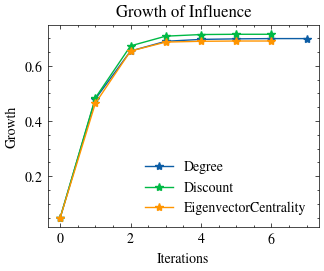

In [10]:
fig, ax = plt.subplots()

hs = [Heuristics.deg_h, Heuristics.deg_discount_h, Heuristics.eigenvector_centrality_h]
names = ["Degree", "Discount", "EigenvectorCentrality"]
growths = []
for i, heuristic in enumerate(hs):
    _, _, g = net.run_ICC(heuristic(net.get_nx(), 50))
    growths.append(g)
for i in range(len(names)):
    ax.plot(growths[i], label=names[i], marker="*")
ax.set_xlabel("Iterations")
ax.set_ylabel("Growth")
ax.set_title("Growth of Influence")
ax.legend()

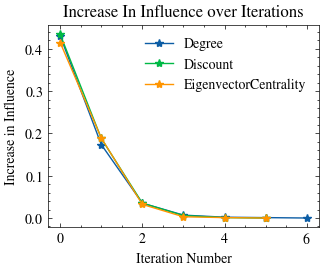

In [29]:
import numpy as np

fig, axs = plt.subplots()
for i, g in enumerate(growths):
    p = np.diff(g, n=1)
    axs.plot(p, label=names[i], marker="*")
axs.set_xlabel("Iteration Number")
axs.set_ylabel("Increase in Influence")
axs.set_title("Increase In Influence over Iterations")
axs.legend()